# Лабораторная работа № 6. Деревья решений и ансамблевые методы
## Ноутбук 2. Этап 3: построение и визуализация дерева решений (вариант 3, `credit_card_fraud_2026.csv`)

In [1]:
# Импорт библиотек
import sys
import random
import warnings

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier

from common import (SEED, CLASS_NAMES, load_data, get_feature_lists, make_preprocessor, split_data,
                    get_feature_names, evaluate, plot_confusion, plot_decision_tree, save_fig)
from metrics import entropy, gini, information_gain

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)

In [2]:
# Данные, разбиение (train/test, stratify, random_state=42) и предобработка – как в ноутбуке 1
df = load_data()
numeric_cols, categorical_cols = get_feature_lists(df)
X_train, X_test, y_train, y_test = split_data(df)

preprocessor = make_preprocessor(numeric_cols, categorical_cols).fit(X_train)   # обучается только на train
feature_names = get_feature_names(preprocessor)
X_train_t = pd.DataFrame(preprocessor.transform(X_train), columns=feature_names, index=X_train.index)
X_test_t = pd.DataFrame(preprocessor.transform(X_test), columns=feature_names, index=X_test.index)
print("train:", X_train_t.shape, " test:", X_test_t.shape)

train: (16000, 54)  test: (4000, 54)


## Задания 3.1–3.3. Мелкое дерево (max_depth = 3) и его визуализация

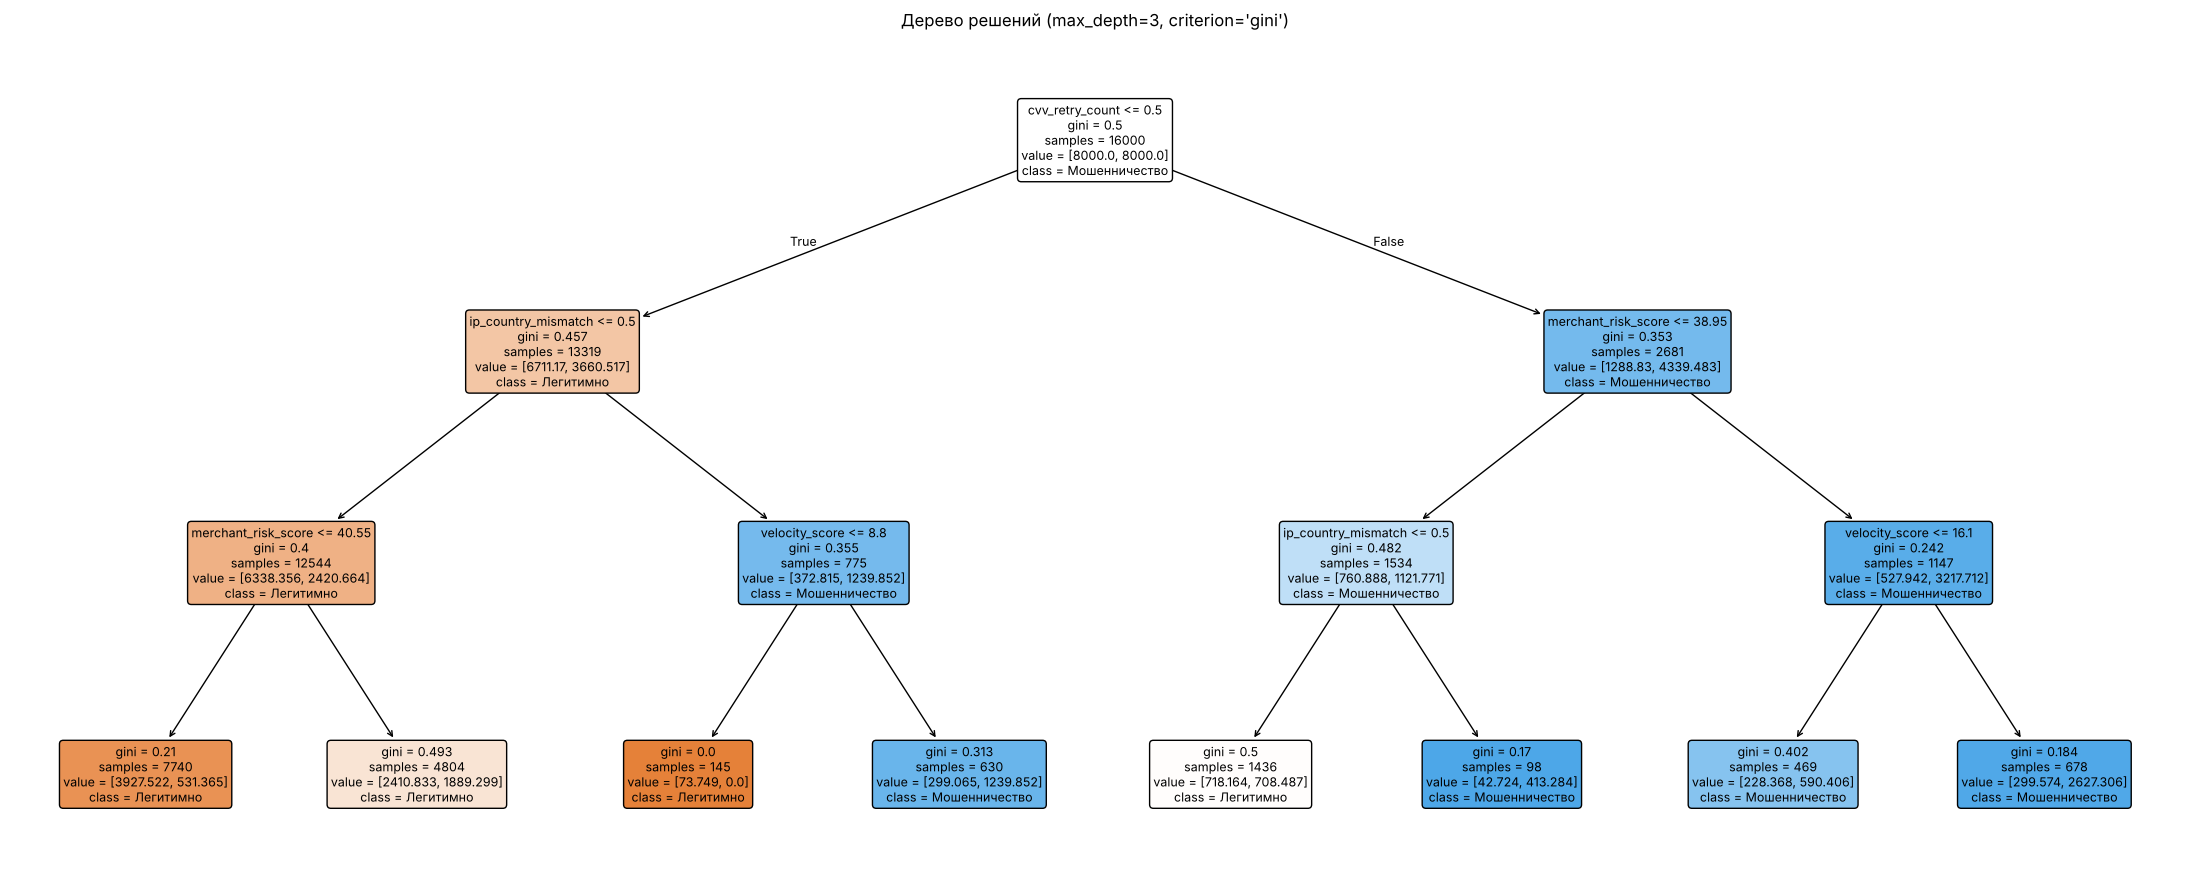

In [3]:
# Задание 3.1. Дерево решений с ограничением глубины max_depth=3 (class_weight='balanced' из-за дисбаланса)
dt3 = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEED)
dt3.fit(X_train_t, y_train)

# Задание 3.1. Визуализация: подписаны feature_names и class_names
plot_decision_tree(dt3, feature_names, title="Дерево решений (max_depth=3, criterion='gini')", figsize=(22, 9))
plt.tight_layout()
save_fig("06_tree_depth3")
plt.show()

**Как читать дерево.** В каждом узле указаны условие разбиения (`признак <= порог`; для one-hot признаков `<= 0,5` означает «категория не равна»),
`gini` – неоднородность узла, `samples` – число объектов, `value` – взвешенное число объектов каждого класса
(из-за `class_weight="balanced"` веса классов выровнены, поэтому в корне `value` ≈ [8000, 8000]), `class` – класс-большинство в узле.
Цвет показывает доминирующий класс, насыщенность – чистоту узла.

               precision    recall  f1-score   support

    Легитимно      0.991     0.895     0.941      3932
Мошенничество      0.080     0.529     0.139        68

     accuracy                          0.889      4000
    macro avg      0.536     0.712     0.540      4000
 weighted avg      0.976     0.889     0.927      4000



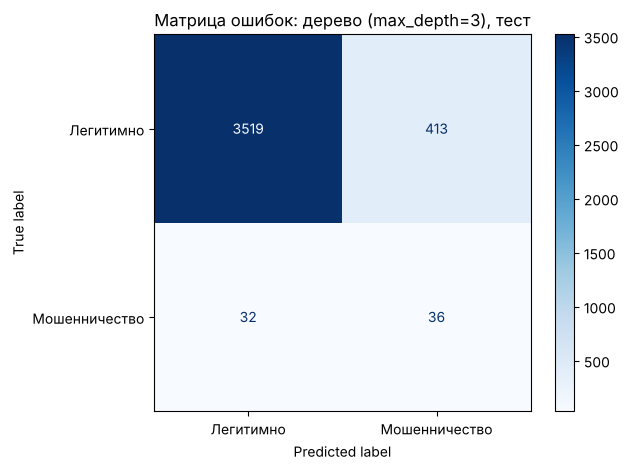

In [4]:
# Задание 3.3. Метрики на тесте и матрица ошибок
def metrics_row(name, model, Xtr, ytr, Xte, yte):
    m = evaluate(model, Xte, yte)
    tr = evaluate(model, Xtr, ytr)
    return {"Модель": name, "Глубина": model.get_depth(), "Листьев": model.get_n_leaves(),
            "Train F1": tr["f1"], "Test accuracy": m["accuracy"], "Test precision": m["precision"],
            "Test recall": m["recall"], "Test F1": m["f1"], "Test ROC-AUC": m["roc_auc"]}

print(classification_report(y_test, dt3.predict(X_test_t), target_names=CLASS_NAMES, digits=3))

plot_confusion(dt3, X_test_t, y_test, title="Матрица ошибок: дерево (max_depth=3), тест")
plt.tight_layout()
save_fig("07_confusion_tree3")
plt.show()

In [5]:
# Задание 3.1 (глубина 4) и 3.4–3.5: дерево без ограничения глубины (min_samples_leaf=10), критерии gini и entropy
trees = {
    "max_depth=3, gini": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEED),
    "max_depth=3, entropy": DecisionTreeClassifier(max_depth=3, criterion="entropy", class_weight="balanced", random_state=SEED),
    "max_depth=4, gini": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED),
    "без ограничения глубины, min_samples_leaf=10, gini": DecisionTreeClassifier(min_samples_leaf=10, class_weight="balanced", random_state=SEED),
    "без ограничения глубины, min_samples_leaf=10, entropy": DecisionTreeClassifier(min_samples_leaf=10, criterion="entropy", class_weight="balanced", random_state=SEED),
}
rows = []
for name, tree in trees.items():
    tree.fit(X_train_t, y_train)
    rows.append(metrics_row(name, tree, X_train_t, y_train, X_test_t, y_test))
comparison = pd.DataFrame(rows).set_index("Модель")
comparison.round(3)

,Глубина,Листьев,Train F1,Test accuracy,Test precision,Test recall,Test F1,Test ROC-AUC
Модель,,,,,,,,
"max_depth=3, gini",3,8,0.154,0.889,0.080,0.529,0.139,0.822
"max_depth=3, entropy",3,8,0.107,0.806,0.054,0.632,0.100,0.795
"max_depth=4, gini",4,15,0.112,0.787,0.056,0.721,0.103,0.834
"без ограничения глубины, min_samples_leaf=10, gini",20,228,0.403,0.928,0.077,0.294,0.122,0.619
"без ограничения глубины, min_samples_leaf=10, entropy",20,216,0.444,0.940,0.090,0.279,0.136,0.616


**Вывод о переобучении.** Дерево без ограничения глубины (глубина 20, ~230 листьев) подстраивается под обучающую выборку:
F1 на train (≈0,40) втрое выше, чем на test (≈0,12), а ROC-AUC на тесте падает до ≈0,62 против ≈0,82–0,83 у мелких деревьев
(глубина 3–4), у которых качество на train и test близко. Высокая accuracy глубокого дерева (≈0,93–0,94) обманчива:
она растёт за счёт того, что дерево реже предсказывает редкий класс (recall ≈0,28–0,29 против 0,53–0,72 у мелких деревьев).
Отдельное глубокое дерево нельзя считать надёжной моделью – для этого и применяются ансамбли.

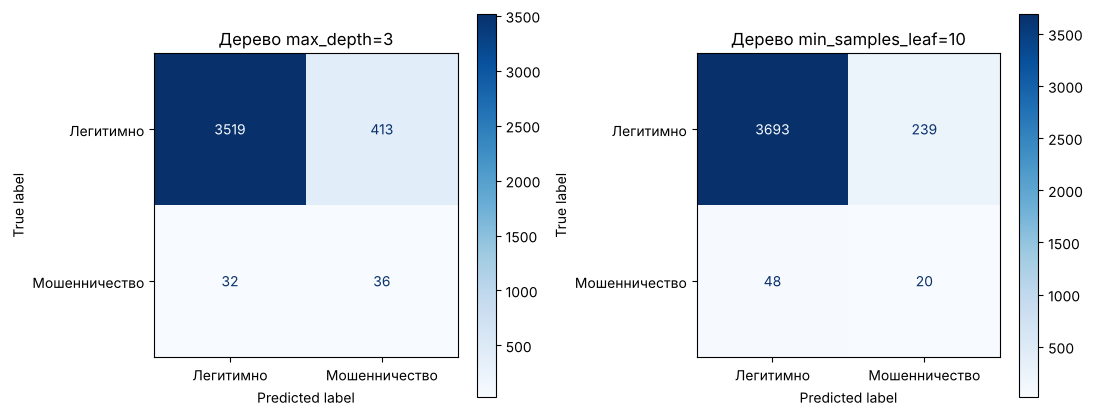

In [6]:
# Задание 3.4. Визуализация матриц ошибок глубокого дерева и мелкого дерева рядом
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(trees["max_depth=3, gini"], X_test_t, y_test, "Дерево max_depth=3", ax=axes[0])
plot_confusion(trees["без ограничения глубины, min_samples_leaf=10, gini"], X_test_t, y_test,
               "Дерево min_samples_leaf=10", ax=axes[1])
plt.tight_layout()
save_fig("08_confusion_tree_shallow_vs_deep")
plt.show()

## Задание 3.5. Критерии gini и entropy, информационный выигрыш
Критерий Джини: G = 1 − Σ pₖ²; энтропия Шеннона: H = −Σ pᵢ·log₂ pᵢ; информационный выигрыш разбиения =
I(родитель) − Σ (nⱼ/n)·I(потомок j). Проверим расчёт вручную на «пне» (дерево глубины 1 без весов классов).

In [7]:
stump = DecisionTreeClassifier(max_depth=1, criterion="entropy", random_state=SEED).fit(X_train_t, y_train)
t = stump.tree_
feat, thr = feature_names[t.feature[0]], t.threshold[0]
ig_sklearn = t.impurity[0] - (t.weighted_n_node_samples[1] * t.impurity[1] +
                              t.weighted_n_node_samples[2] * t.impurity[2]) / t.weighted_n_node_samples[0]
mask = (X_train_t[feat] <= thr).values
print(f"Корневое разбиение: {feat} <= {thr:.2f}")
print(f"Энтропия родителя H = {entropy(y_train):.4f},   индекс Джини G = {gini(y_train):.4f}")
print(f"Информационный выигрыш вручную (entropy): {information_gain(y_train, mask, entropy):.5f}")
print(f"Информационный выигрыш по данным sklearn:   {ig_sklearn:.5f}")
print(f"Уменьшение Джини при том же разбиении:       {information_gain(y_train, mask, gini):.5f}")

Корневое разбиение: cvv_retry_count <= 0.50
Энтропия родителя H = 0.1239,   индекс Джини G = 0.0333
Информационный выигрыш вручную (entropy): 0.00909
Информационный выигрыш по данным sklearn:   0.00909
Уменьшение Джини при том же разбиении:       0.00058


**Сравнение gini и entropy.** На мелком дереве (глубина 3) критерий gini дал чуть лучшие ROC-AUC и F1 (0,822 и 0,139 против 0,795 и 0,100),
у глубокого дерева результаты почти совпадают (F1 0,122 и 0,136, ROC-AUC 0,619 и 0,616). Так как в тесте всего 68 мошеннических
транзакций, такие различия сопоставимы со случайными колебаниями; влияние глубины и ограничений на листья существенно больше,
чем влияние критерия. Информационный выигрыш корневого разбиения, посчитанный вручную, совпал с расчётом sklearn.